In [ ]:

# Notebook 02: Exploratory Data Analysis
# Step 6.2: Environment Setup

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import zipfile

from google.colab import files

sns.set_theme(style="whitegrid")

print("EDA environment ready!")

uploaded = files.upload()


EDA environment ready!


Saving cleaned_data.zip to cleaned_data.zip


In [ ]:

# Step 6.3: Load Cleaned Master Dataset

# Extract the ZIP file
with zipfile.ZipFile("cleaned_data.zip", "r") as zip_ref:
    zip_ref.extractall("/content/cleaned_data")

# Load the master dataset
df = pd.read_csv(
    "/content/cleaned_data/master_dataset.csv",
    parse_dates=["booked_on", "appt_date"]
)

# Validate dataset dimensions
assert df.shape == (1000, 24)
assert df["appointment_id"].is_unique

print("MASTER DATASET SUMMARY")
print("=" * 40)

print("Total appointments:", len(df))
print("Total columns:", df.shape[1])
print("Total clinics:", df["clinic_id"].nunique())
print("Total cities:", df["city"].nunique())
print("Duplicate appointment IDs:",
      df["appointment_id"].duplicated().sum())

print("\nMaster dataset loaded successfully!")


MASTER DATASET SUMMARY
Total appointments: 1000
Total columns: 24
Total clinics: 8
Total cities: 6
Duplicate appointment IDs: 0

Master dataset loaded successfully!


In [ ]:

# Step 6.4: Healthcare Performance KPIs

total_appointments = len(df)

attended = df["status"].eq("Attended").sum()
no_shows = df["status"].eq("No-Show").sum()

known_outcomes = attended + no_shows
unknown_status = total_appointments - known_outcomes

attendance_rate = attended / known_outcomes * 100
no_show_rate = no_shows / known_outcomes * 100

# Potential fee revenue associated with no-shows
revenue_at_risk = df.loc[
    df["status"] == "No-Show", "fee_inr"
].sum()

kpi_report = pd.DataFrame({
    "Metric": [
        "Total Appointments",
        "Attended Appointments",
        "No-Show Appointments",
        "Unknown Outcomes",
        "Attendance Rate (%)",
        "No-Show Rate (%)",
        "Potential Revenue at Risk (INR)",
        "Average Lead Time (Days)"
    ],
    "Value": [
        total_appointments,
        attended,
        no_shows,
        unknown_status,
        round(attendance_rate, 2),
        round(no_show_rate, 2),
        revenue_at_risk,
        round(df["lead_time_days"].mean(), 2)
    ]
})

print("HEALTHCARE PERFORMANCE SCORECARD")
print("=" * 45)

display(kpi_report)


HEALTHCARE PERFORMANCE SCORECARD


,Metric,Value
0,Total Appointments,1000.00
1,Attended Appointments,777.00
2,No-Show Appointments,219.00
3,Unknown Outcomes,4.00
4,Attendance Rate (%),78.01
5,No-Show Rate (%),21.99
6,Potential Revenue at Risk (INR),152050.00
7,Average Lead Time (Days),11.83


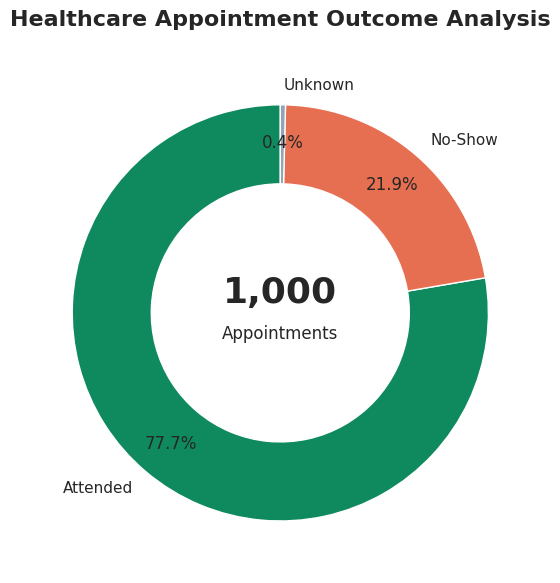

Visualization saved successfully!


In [ ]:

# Step 6.5: Appointment Outcome Visualization

import os

os.makedirs("/content/eda_outputs", exist_ok=True)

status_counts = (
    df["status"]
    .fillna("Unknown")
    .value_counts()
    .reindex(["Attended", "No-Show", "Unknown"])
)

fig, ax = plt.subplots(figsize=(9, 6))

colors = ["#0F8A5F", "#E76F51", "#94A3B8"]

wedges, texts, autotexts = ax.pie(
    status_counts.values,
    labels=status_counts.index,
    autopct="%1.1f%%",
    startangle=90,
    colors=colors,
    pctdistance=0.82,
    wedgeprops={
        "width": 0.38,
        "edgecolor": "white"
    }
)

ax.text(
    0, 0.05, f"{len(df):,}",
    ha="center",
    fontsize=26,
    fontweight="bold"
)

ax.text(
    0, -0.12, "Appointments",
    ha="center",
    fontsize=12
)

ax.set_title(
    "Healthcare Appointment Outcome Analysis",
    fontsize=16,
    fontweight="bold",
    pad=20
)

plt.tight_layout()

plt.savefig(
    "/content/eda_outputs/01_appointment_outcomes.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

print("Visualization saved successfully!")


CLINIC PERFORMANCE SCORECARD


,Total_Appointments,Attended,No_Shows,Unknown,No_Show_Rate_Pct,Revenue_at_Risk_INR
clinic_name,,,,,,
Gomti Nagar Care Point,92,61,31,0,33.70,20650
Hadapsar Care Centre,145,106,39,0,26.90,29550
Malviya Nagar Clinic,143,104,38,1,26.76,23200
Kothrud Family Clinic,162,124,36,2,22.50,26800
Vijay Nagar Clinic,101,80,21,0,20.79,17350
Edappally Medical Centre,142,119,23,0,16.20,15150
Sitabuldi Health Point,85,71,13,1,15.48,8000
Vaishali Nagar Clinic,130,112,18,0,13.85,11350


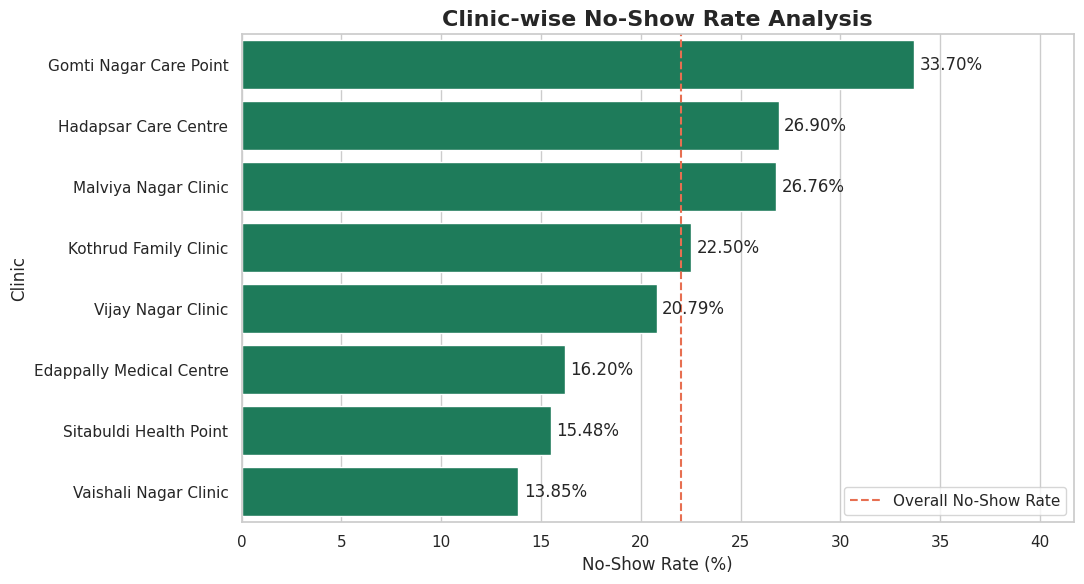

In [ ]:

# Step 6.6: Clinic-wise Performance Analysis

clinic_report = df.groupby("clinic_name").agg(
    Total_Appointments=("appointment_id", "count"),
    Attended=("status", lambda x: (x == "Attended").sum()),
    No_Shows=("status", lambda x: (x == "No-Show").sum()),
    Unknown=("status", lambda x: x.isna().sum())
)

# Calculate no-show percentage
clinic_report["No_Show_Rate_Pct"] = (
    clinic_report["No_Shows"] /
    (clinic_report["Attended"] + clinic_report["No_Shows"])
    * 100
).round(2)

# Calculate potential revenue at risk
clinic_report["Revenue_at_Risk_INR"] = (
    df[df["status"] == "No-Show"]
    .groupby("clinic_name")["fee_inr"]
    .sum()
)

clinic_report["Revenue_at_Risk_INR"] = (
    clinic_report["Revenue_at_Risk_INR"].fillna(0)
)

clinic_report = clinic_report.sort_values(
    "No_Show_Rate_Pct", ascending=False
)

print("CLINIC PERFORMANCE SCORECARD")
display(clinic_report)

# Create horizontal bar chart
plt.figure(figsize=(11, 6))

ax = sns.barplot(
    x="No_Show_Rate_Pct",
    y=clinic_report.index,
    data=clinic_report,
    color="#0F8A5F"
)

ax.bar_label(ax.containers[0], fmt="%.2f%%", padding=4)

plt.axvline(
    no_show_rate,
    color="#E76F51",
    linestyle="--",
    label="Overall No-Show Rate"
)

plt.title("Clinic-wise No-Show Rate Analysis",
          fontsize=16, fontweight="bold")

plt.xlabel("No-Show Rate (%)")
plt.ylabel("Clinic")
plt.xlim(0, max(clinic_report["No_Show_Rate_Pct"].max(),
                no_show_rate) + 8)
plt.legend()
plt.tight_layout()

plt.savefig(
    "/content/eda_outputs/02_clinic_performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


REMINDER EFFECTIVENESS REPORT


,Total,Attended,No_Shows,No_Show_Rate_Pct
reminder_sent,,,,
No,431,298,133,30.86
Yes,565,479,86,15.22


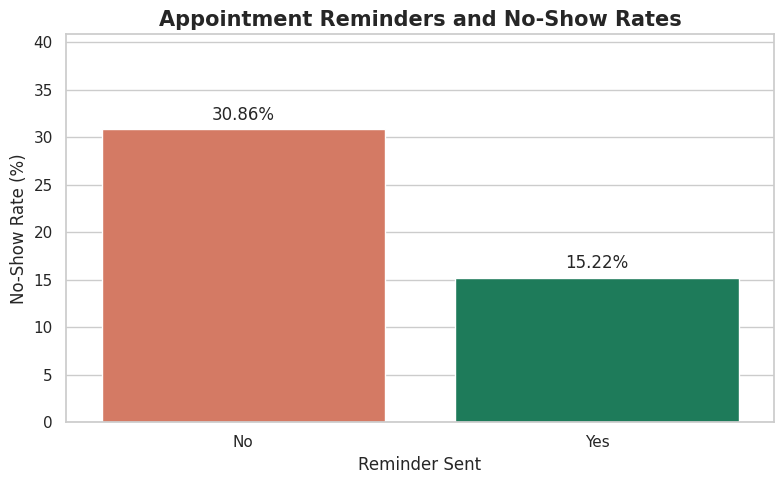

In [ ]:

# Step 6.7: Reminder Effectiveness Analysis

# Include only known appointment outcomes
known_df = df[df["status"].isin(
    ["Attended", "No-Show"]
)].copy()

# Calculate reminder-wise performance
reminder_report = known_df.groupby(
    "reminder_sent"
).agg(
    Total=("appointment_id", "count"),
    Attended=("status", lambda x: (x == "Attended").sum()),
    No_Shows=("status", lambda x: (x == "No-Show").sum())
)

reminder_report["No_Show_Rate_Pct"] = (
    reminder_report["No_Shows"] /
    reminder_report["Total"] * 100
).round(2)

print("REMINDER EFFECTIVENESS REPORT")
display(reminder_report)

# Create visualization
plt.figure(figsize=(8, 5))

ax = sns.barplot(
    data=reminder_report.reset_index(),
    x="reminder_sent",
    y="No_Show_Rate_Pct",
    hue="reminder_sent",
    palette={"Yes": "#0F8A5F", "No": "#E76F51"},
    legend=False
)

for container in ax.containers:
    ax.bar_label(container, fmt="%.2f%%", padding=4)

plt.title("Appointment Reminders and No-Show Rates",
          fontsize=15, fontweight="bold")

plt.xlabel("Reminder Sent")
plt.ylabel("No-Show Rate (%)")
plt.ylim(0, reminder_report["No_Show_Rate_Pct"].max() + 10)

plt.tight_layout()

plt.savefig(
    "/content/eda_outputs/03_reminder_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


BOOKING CHANNEL PERFORMANCE


,Total,Attended,No_Shows,No_Show_Rate_Pct
booking_channel,,,,
Phone,358,258,100,27.93
Walk-in,253,202,51,20.16
App,385,317,68,17.66


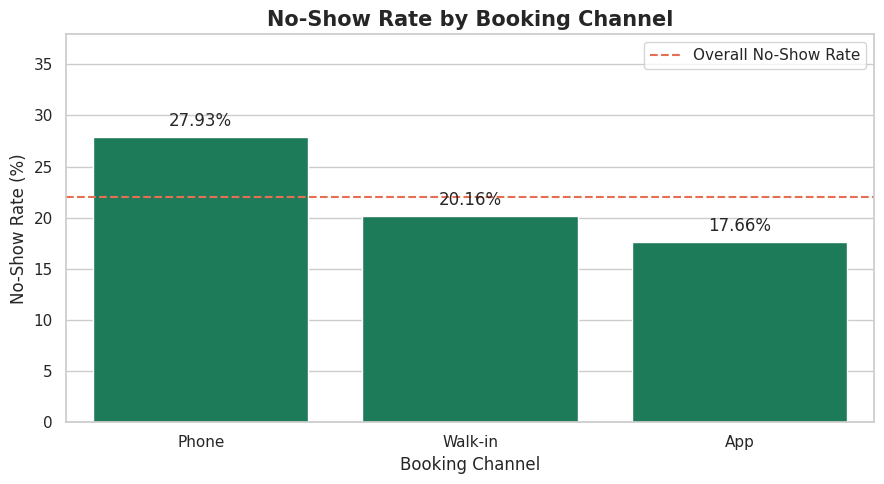

In [ ]:

# Step 6.8: Booking Channel Analysis

channel_report = known_df.groupby(
    "booking_channel"
).agg(
    Total=("appointment_id", "count"),
    Attended=("status", lambda x: (x == "Attended").sum()),
    No_Shows=("status", lambda x: (x == "No-Show").sum())
)

channel_report["No_Show_Rate_Pct"] = (
    channel_report["No_Shows"] /
    channel_report["Total"] * 100
).round(2)

channel_report = channel_report.sort_values(
    "No_Show_Rate_Pct", ascending=False
)

print("BOOKING CHANNEL PERFORMANCE")
display(channel_report)

plt.figure(figsize=(9, 5))

ax = sns.barplot(
    data=channel_report.reset_index(),
    x="booking_channel",
    y="No_Show_Rate_Pct",
    color="#0F8A5F"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.2f%%",
    padding=5
)

plt.axhline(
    no_show_rate,
    color="#E76F51",
    linestyle="--",
    label="Overall No-Show Rate"
)

plt.title(
    "No-Show Rate by Booking Channel",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Booking Channel")
plt.ylabel("No-Show Rate (%)")

plt.ylim(
    0,
    max(channel_report["No_Show_Rate_Pct"].max(),
        no_show_rate) + 10
)

plt.legend()
plt.tight_layout()

plt.savefig(
    "/content/eda_outputs/04_booking_channel.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



NO-SHOW RATE BY AGE GROUP


,Total,No_Shows,No_Show_Rate_Pct
age_group,,,
0-18,4,1,25.00
19-35,270,75,27.78
36-50,259,52,20.08
51-65,248,42,16.94
66+,199,45,22.61


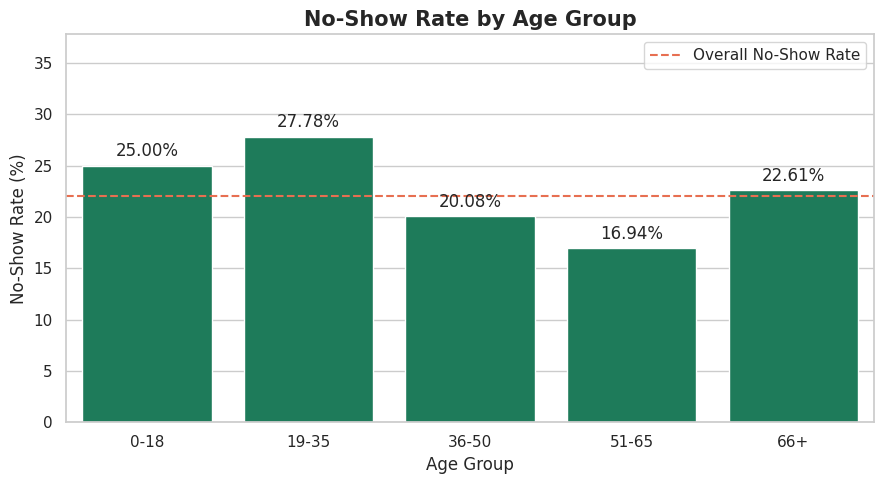


NO-SHOW RATE BY TRAVEL DISTANCE


,Total,No_Shows,No_Show_Rate_Pct
distance_group,,,
0-5 km,288,53,18.40
5-10 km,282,51,18.09
10-20 km,336,81,24.11
20+ km,70,24,34.29


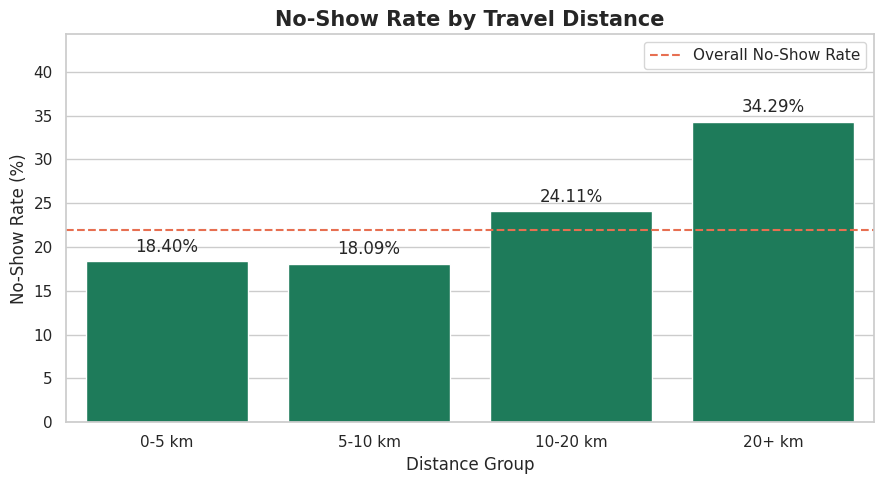

In [ ]:

# Step 6.9: Age and Distance Analysis

# Create age groups
known_df["age_group"] = pd.cut(
    known_df["age"],
    bins=[0, 18, 35, 50, 65, 120],
    labels=["0-18", "19-35", "36-50", "51-65", "66+"],
    include_lowest=True
)

# Create distance groups
known_df["distance_group"] = pd.cut(
    known_df["distance_km"],
    bins=[0, 5, 10, 20, np.inf],
    labels=["0-5 km", "5-10 km", "10-20 km", "20+ km"],
    include_lowest=True
)

# Create binary no-show indicator
known_df["is_no_show"] = (
    known_df["status"] == "No-Show"
).astype(int)

# Generate grouped reports and charts
reports = {}

for col, title, filename in [
    ("age_group", "No-Show Rate by Age Group",
     "05_age_analysis.png"),
    ("distance_group", "No-Show Rate by Travel Distance",
     "06_distance_analysis.png")
]:

    report = known_df.groupby(
        col, observed=True
    ).agg(
        Total=("is_no_show", "count"),
        No_Shows=("is_no_show", "sum")
    )

    report["No_Show_Rate_Pct"] = (
        report["No_Shows"] / report["Total"] * 100
    ).round(2)

    reports[col] = report

    print("\n" + title.upper())
    display(report)

    plt.figure(figsize=(9, 5))

    ax = sns.barplot(
        data=report.reset_index(),
        x=col,
        y="No_Show_Rate_Pct",
        color="#0F8A5F"
    )

    ax.bar_label(
        ax.containers[0],
        fmt="%.2f%%",
        padding=4
    )

    plt.axhline(
        no_show_rate,
        color="#E76F51",
        linestyle="--",
        label="Overall No-Show Rate"
    )

    plt.title(title, fontsize=15, fontweight="bold")
    plt.xlabel(col.replace("_", " ").title())
    plt.ylabel("No-Show Rate (%)")
    plt.ylim(0, max(report["No_Show_Rate_Pct"].max(),
                    no_show_rate) + 10)
    plt.legend()
    plt.tight_layout()

    plt.savefig(
        f"/content/eda_outputs/{filename}",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


APPOINTMENT LEAD TIME ANALYSIS


,Total,No_Shows,No_Show_Rate_Pct
lead_time_group,,,
0-3 Days,136,18,13.24
4-7 Days,254,45,17.72
8-14 Days,304,53,17.43
15-30 Days,253,76,30.04
31+ Days,43,26,60.47


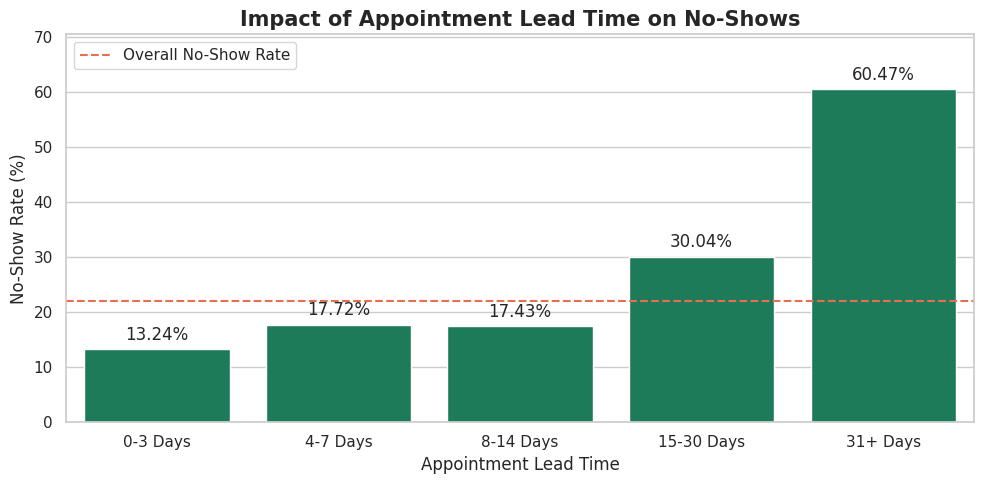

In [ ]:

# Step 6.10: Appointment Lead Time Analysis

known_df["lead_time_group"] = pd.cut(
    known_df["lead_time_days"],
    bins=[0, 3, 7, 14, 30, np.inf],
    labels=[
        "0-3 Days",
        "4-7 Days",
        "8-14 Days",
        "15-30 Days",
        "31+ Days"
    ],
    include_lowest=True
)

lead_report = known_df.groupby(
    "lead_time_group", observed=True
).agg(
    Total=("is_no_show", "count"),
    No_Shows=("is_no_show", "sum")
)

lead_report["No_Show_Rate_Pct"] = (
    lead_report["No_Shows"] /
    lead_report["Total"] * 100
).round(2)

print("APPOINTMENT LEAD TIME ANALYSIS")
display(lead_report)

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=lead_report.reset_index(),
    x="lead_time_group",
    y="No_Show_Rate_Pct",
    color="#0F8A5F"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.2f%%",
    padding=4
)

plt.axhline(
    no_show_rate,
    color="#E76F51",
    linestyle="--",
    label="Overall No-Show Rate"
)

plt.title(
    "Impact of Appointment Lead Time on No-Shows",
    fontsize=15,
    fontweight="bold"
)

plt.xlabel("Appointment Lead Time")
plt.ylabel("No-Show Rate (%)")

plt.ylim(
    0,
    max(lead_report["No_Show_Rate_Pct"].max(),
        no_show_rate) + 10
)

plt.legend()
plt.tight_layout()

plt.savefig(
    "/content/eda_outputs/07_lead_time_analysis.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()


In [ ]:

# Step 6.11: Business Insights and Recommendations

insights = pd.DataFrame({
    "Analysis": [
        "Overall Appointment Performance",
        "Potential Revenue at Risk",
        "Reminder Analysis",
        "Booking Channel Analysis",
        "Lead Time Analysis",
        "Clinic Performance"
    ],

    "Key_Finding": [
        f"No-show rate: {no_show_rate:.2f}%",
        f"INR {revenue_at_risk:,.0f} in potential fees",
        "Without reminder: 30.86%; With reminder: 15.22%",
        "Phone bookings have the highest no-show rate",
        "31+ day appointments have a 60.47% no-show rate",
        f"{clinic_report.index[0]} has the highest no-show rate"
    ],

    "Recommendation": [
        "Monitor appointment attendance regularly",
        "Introduce proactive appointment confirmations",
        "Test expanded automated reminder systems",
        "Prioritize confirmation calls for phone bookings",
        "Offer earlier slots and reconfirm long-wait bookings",
        "Investigate clinic-specific operational challenges"
    ],

    "Priority": [
        "High",
        "High",
        "High",
        "Medium",
        "High",
        "High"
    ]
})

print("STRATEGIC BUSINESS INSIGHTS")
print("=" * 45)

display(insights)

insights.to_csv(
    "/content/eda_outputs/business_insights.csv",
    index=False
)

print("\nBusiness insights exported successfully!")

print("\nDISTANCE ANALYSIS REVIEW")
display(reports["distance_group"])

print("\nLEAD TIME ANALYSIS REVIEW")
display(lead_report)


STRATEGIC BUSINESS INSIGHTS


,Analysis,Key_Finding,Recommendation,Priority
0,Overall Appointment Performance,No-show rate: 21.99%,Monitor appointment attendance regularly,High
1,Potential Revenue at Risk,"INR 152,050 in potential fees",Introduce proactive appointment confirmations,High
2,Reminder Analysis,Without reminder: 30.86%; With reminder: 15.22%,Test expanded automated reminder systems,High
3,Booking Channel Analysis,Phone bookings have the highest no-show rate,Prioritize confirmation calls for phone bookings,Medium
4,Lead Time Analysis,31+ day appointments have a 60.47% no-show rate,Offer earlier slots and reconfirm long-wait bo...,High
5,Clinic Performance,Gomti Nagar Care Point has the highest no-show...,Investigate clinic-specific operational challe...,High



Business insights exported successfully!

DISTANCE ANALYSIS REVIEW


,Total,No_Shows,No_Show_Rate_Pct
distance_group,,,
0-5 km,288,53,18.40
5-10 km,282,51,18.09
10-20 km,336,81,24.11
20+ km,70,24,34.29



LEAD TIME ANALYSIS REVIEW


,Total,No_Shows,No_Show_Rate_Pct
lead_time_group,,,
0-3 Days,136,18,13.24
4-7 Days,254,45,17.72
8-14 Days,304,53,17.43
15-30 Days,253,76,30.04
31+ Days,43,26,60.47


In [ ]:

# Step 6.12: Export EDA Results

import os
import shutil
from google.colab import files

output_dir = "/content/eda_outputs"

# Export analytical reports
kpi_report.to_csv(
    f"{output_dir}/kpi_report.csv",
    index=False
)

clinic_report.to_csv(
    f"{output_dir}/clinic_report.csv"
)

reminder_report.to_csv(
    f"{output_dir}/reminder_report.csv"
)

channel_report.to_csv(
    f"{output_dir}/booking_channel_report.csv"
)

reports["age_group"].to_csv(
    f"{output_dir}/age_report.csv"
)

reports["distance_group"].to_csv(
    f"{output_dir}/distance_report.csv"
)

lead_report.to_csv(
    f"{output_dir}/lead_time_report.csv"
)

# Display exported files
print("EDA EXPORT REPORT")
print("=" * 40)

for filename in sorted(os.listdir(output_dir)):
    print(filename)

print("\nTotal files:", len(os.listdir(output_dir)))

# Create ZIP backup
shutil.make_archive(
    "/content/eda_outputs",
    "zip",
    output_dir
)

print("\nNotebook 02 completed!")
print("Downloading EDA results...")

files.download("/content/eda_outputs.zip")


EDA EXPORT REPORT
01_appointment_outcomes.png
02_clinic_performance.png
03_reminder_analysis.png
04_booking_channel.png
05_age_analysis.png
06_distance_analysis.png
07_lead_time_analysis.png
age_report.csv
booking_channel_report.csv
business_insights.csv
clinic_report.csv
distance_report.csv
kpi_report.csv
lead_time_report.csv
reminder_report.csv

Total files: 15

Notebook 02 completed!


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>